# Data Analysis & Visualization (DAV) — Lab 4
## The Analytical Ladder: Univariate, Bivariate, and Multivariate Analysis
---
- **Student Roll Number:** `24i-2514`
- **Section:** `DS-5B`
- **Course:** Data Analysis and Visualization (DAV)
- **Dataset:** Food Delivery Orders Dataset (`food_delivery_orders.csv`)
---

## Step 0: Imports and Dataset Setup
We import standard data analysis and visualization libraries (`pandas`, `numpy`, `matplotlib.pyplot`, `seaborn`) and load the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean default theme
sns.set_theme(style="whitegrid")

# Load food delivery orders dataset
df = pd.read_csv('food_delivery_orders.csv')

# Parse date column
df['order_date'] = pd.to_datetime(df['order_date'])

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (4200, 9)


,order_date,city,restaurant_category,cuisine,order_value,discount_percent,delivery_time_min,rating,profit_per_order
0,2023-01-01,Karachi,Fine Dining,Continental,2768.0,25.0,36.2,4.5,95.0
1,2023-01-01,Karachi,Fine Dining,Steakhouse,4979.0,44.8,23.3,4.8,-437.0
2,2023-01-01,Karachi,Cloud Kitchen,Indian,4008.0,11.9,39.6,4.2,618.0
3,2023-01-01,Islamabad,Fine Dining,Steakhouse,3260.0,8.3,35.8,4.5,423.0
4,2023-01-01,Karachi,Fast Food,Pizza,435.0,13.5,29.4,4.8,53.0


In [2]:
# Check basic info and missing values
df.info()
print("\nMissing values check:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_date           4200 non-null   datetime64[ns]
 1   city                 4200 non-null   object        
 2   restaurant_category  4200 non-null   object        
 3   cuisine              4200 non-null   object        
 4   order_value          4200 non-null   float64       
 5   discount_percent     4200 non-null   float64       
 6   delivery_time_min    4200 non-null   float64       
 7   rating               4200 non-null   float64       
 8   profit_per_order     4200 non-null   float64       
dtypes: datetime64[ns](1), float64(5), object(3)
memory usage: 295.4+ KB

Missing values check:
order_date             0
city                   0
restaurant_category    0
cuisine                0
order_value            0
discount_percent       0
delivery_time_min    

---
## Task 1: Univariate, Properly Read
> **Prompt:** Management wants to advertise a single number for "typical delivery time." Plot a histogram with KDE overlay of `delivery_time_min`, report its skewness value, and compare mean vs. median. In 1-2 sentences, recommend whether the mean or median is the more honest number to advertise, and why.

Mean Delivery Time:   34.54 minutes
Median Delivery Time: 32.50 minutes
Skewness:             2.877


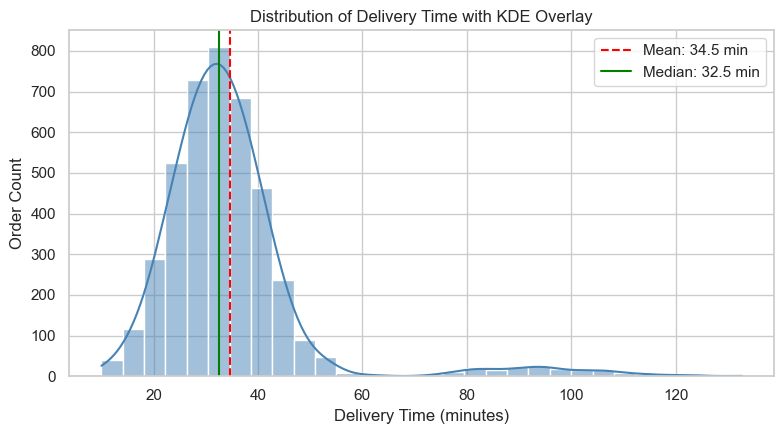

In [3]:
# Calculate mean, median, and skewness
mean_time = df['delivery_time_min'].mean()
median_time = df['delivery_time_min'].median()
skew_time = df['delivery_time_min'].skew()

print(f"Mean Delivery Time:   {mean_time:.2f} minutes")
print(f"Median Delivery Time: {median_time:.2f} minutes")
print(f"Skewness:             {skew_time:.3f}")

# Histogram with KDE overlay
plt.figure(figsize=(8, 4.5))
sns.histplot(df['delivery_time_min'], kde=True, bins=30, color='steelblue')
plt.axvline(mean_time, color='red', linestyle='--', label=f'Mean: {mean_time:.1f} min')
plt.axvline(median_time, color='green', linestyle='-', label=f'Median: {median_time:.1f} min')
plt.title('Distribution of Delivery Time with KDE Overlay')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Order Count')
plt.legend()
plt.tight_layout()
plt.show()

**Analysis & Recommendation:**
- **Skewness:** $+2.877$ (strongly positive/right-skewed).
- **Comparison:** The mean ($34.54$ min) is higher than the median ($32.50$ min) because a long right tail of delayed orders (ranging up to $132.7$ min) pulls the average upward.
- **Recommendation:** Management should advertise the **median ($32.5$ minutes)** because it represents the actual 50th-percentile typical experience for customers, whereas the mean is distorted by extreme operational delays.

---
## Task 2: Categorical $\times$ Numerical, Beyond the Average
> **Prompt:** For rating by city, build a violin plot and a strip plot (jittered) of the same data. Which city shows the most inconsistent customer experience — a wide spread or a bimodal pattern, rather than just a low average rating? Explain in 1-2 sentences.

In [4]:
# Summary of rating by city
print(df.groupby('city')['rating'].agg(['count', 'mean', 'std', 'min', 'max']).round(2))

            count  mean   std  min  max
city                                   
Faisalabad    492  4.49  0.38  2.6  5.0
Islamabad     835  4.51  0.37  2.8  5.0
Karachi      1163  4.51  0.38  2.7  5.0
Lahore       1324  4.51  0.40  2.5  5.0
Multan        386  4.52  0.40  2.4  5.0


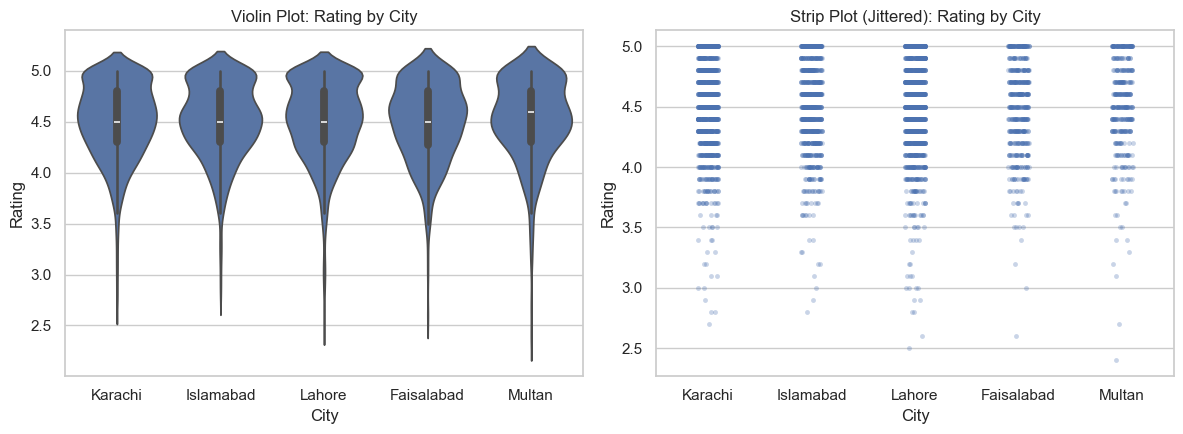

In [5]:
# Violin plot and Strip plot side-by-side
plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.violinplot(data=df, x='city', y='rating')
plt.title('Violin Plot: Rating by City')
plt.xlabel('City')
plt.ylabel('Rating')

plt.subplot(1, 2, 2)
sns.stripplot(data=df, x='city', y='rating', jitter=True, alpha=0.3, size=3.5)
plt.title('Strip Plot (Jittered): Rating by City')
plt.xlabel('City')
plt.ylabel('Rating')

plt.tight_layout()
plt.show()

**Analysis:**
While the average rating across all five cities is nearly identical (~$4.50$), **Multan** (followed closely by **Lahore**) shows the most inconsistent customer experience, exhibiting the widest spread with a long downward tail reaching down to $2.4$ / $2.5$. In contrast, cities like Islamabad and Faisalabad maintain a much tighter, more predictable cluster around $4.5$–$5.0$.

---
## Task 3: Multivariate Encoding
> **Prompt:** Build a single scatter plot of `delivery_time_min` vs. `rating` encoding a 3rd variable via hue (`city`) and a 4th via size (`order_value`). State one pattern — about whether high-value orders get faster or better-rated delivery — that is only visible because of the 4-variable encoding.

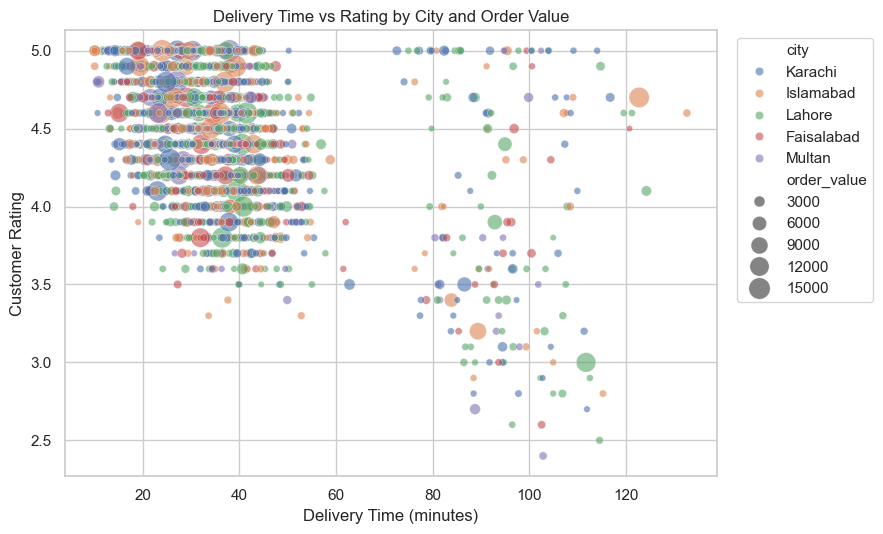

In [6]:
# Scatter plot encoding 4 variables
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=df, 
    x='delivery_time_min', 
    y='rating', 
    hue='city', 
    size='order_value', 
    sizes=(20, 250), 
    alpha=0.6
)
plt.title('Delivery Time vs Rating by City and Order Value')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Customer Rating')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Identified Pattern:**
High-value orders (larger bubbles) are heavily concentrated in the top-left region with faster delivery times ($< 40$ minutes) and high ratings ($4.5$–$5.0$) across all cities. This reveals that restaurants and couriers prioritize fast delivery for high-ticket orders to protect customer satisfaction, while almost all extreme delays ($> 60$ minutes) belong to lower-value orders.

---
## Task 4: Correlation, Pearson vs. Spearman
> **Prompt:** Compute both correlation matrices for the numeric columns. Identify the one pair where the two methods disagree the most, and determine whether the disagreement is driven by a handful of extreme orders or by a genuinely non-linear trend. Decide, and justify, whether those extreme orders should be dropped before reporting the correlation to management. Include the required correlation-is-not-causation caveat in your write-up.

In [7]:
# Numeric correlation matrices
num_cols = ['order_value', 'discount_percent', 'delivery_time_min', 'rating', 'profit_per_order']

pearson_corr = df[num_cols].corr(method='pearson')
spearman_corr = df[num_cols].corr(method='spearman')

print("=== Pearson Correlation (Linear) ===")
print(pearson_corr.round(3))

print("\n=== Spearman Correlation (Rank) ===")
print(spearman_corr.round(3))

print("\n=== Absolute Difference |Pearson - Spearman| ===")
print((pearson_corr - spearman_corr).abs().round(3))

=== Pearson Correlation (Linear) ===
                   order_value  discount_percent  delivery_time_min  rating  \
order_value              1.000            -0.011              0.002   0.003   
discount_percent        -0.011             1.000              0.013  -0.006   
delivery_time_min        0.002             0.013              1.000  -0.445   
rating                   0.003            -0.006             -0.445   1.000   
profit_per_order        -0.657            -0.082             -0.031   0.014   

                   profit_per_order  
order_value                  -0.657  
discount_percent             -0.082  
delivery_time_min            -0.031  
rating                        0.014  
profit_per_order              1.000  

=== Spearman Correlation (Rank) ===
                   order_value  discount_percent  delivery_time_min  rating  \
order_value              1.000             0.008             -0.020   0.004   
discount_percent         0.008             1.000              0.0

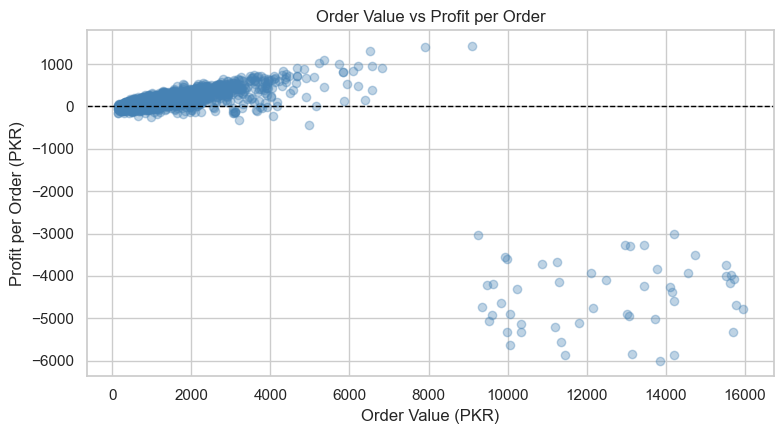

In [8]:
# Scatter plot showing the disagreement between order_value and profit_per_order
plt.figure(figsize=(8, 4.5))
plt.scatter(df['order_value'], df['profit_per_order'], alpha=0.35, color='steelblue')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('Order Value vs Profit per Order')
plt.xlabel('Order Value (PKR)')
plt.ylabel('Profit per Order (PKR)')
plt.tight_layout()
plt.show()

**Analysis & Executive Decision:**
1. **Largest Disagreement:** The two methods disagree the most on **`order_value` vs. `profit_per_order`** (Pearson is **$-0.657$**, but Spearman is **$+0.673$**, a massive difference of **$1.330$**).
2. **Root Cause:** The disagreement is driven by a handful of extreme leverage orders (~70 orders out of 4,200, less than $2\%$). For standard orders ($\\le 5,000$ PKR), higher order value produces higher profit ($r = +0.765$). However, approximately 70 orders with very high order values ($> 5,000$ PKR) incurred catastrophic losses (down to $-5,994$ PKR). Pearson's formula is heavily sensitive to these outliers and turns negative, whereas Spearman relies on ranks and correctly captures the overall positive trend.
3. **Outlier Decision:** These orders **should not be silently dropped**, because they represent real, large financial losses. Instead, report the positive monotonic trend to operations, but report these high-value loss orders separately to management as a high-risk group that needs operational investigation.
4. **Causation Caveat:** *Correlation is not causation* — observing a correlation between delivery time and customer rating ($-0.445$) does not prove delivery delays alone caused the lower ratings, as third factors like kitchen errors or food temperature may be involved.

---
## Task 5: Layered Aggregation
> **Prompt:** Using `pivot_table`, build a `city` $\times$ `restaurant_category` table of average `profit_per_order` (not total revenue) with `margins=True`. Render it as a heatmap with a diverging palette (recall Lab 3's color rules - profit can be negative) and state which combination is most profitable per order. In one sentence, note whether that combination is also the top revenue generator, or whether high revenue and high profitability point to different combinations.

Average Profit per Order (PKR):
restaurant_category  Cafe  Cloud Kitchen  Dessert  Fast Food  Fine Dining  \
city                                                                        
Faisalabad           67.3           65.8    -70.3       20.2        293.7   
Islamabad           -13.5           57.0    -27.9       37.2        153.1   
Karachi             -38.9          136.7     75.2       15.4        302.8   
Lahore               52.3          137.6     65.5       10.6        159.8   
Multan               60.1          -82.8     55.9      -40.8        285.2   
All                  14.6           91.8     31.3       13.6        228.9   

restaurant_category   All  
city                       
Faisalabad           51.9  
Islamabad            35.5  
Karachi              74.1  
Lahore               71.6  
Multan               12.6  
All                  57.4  


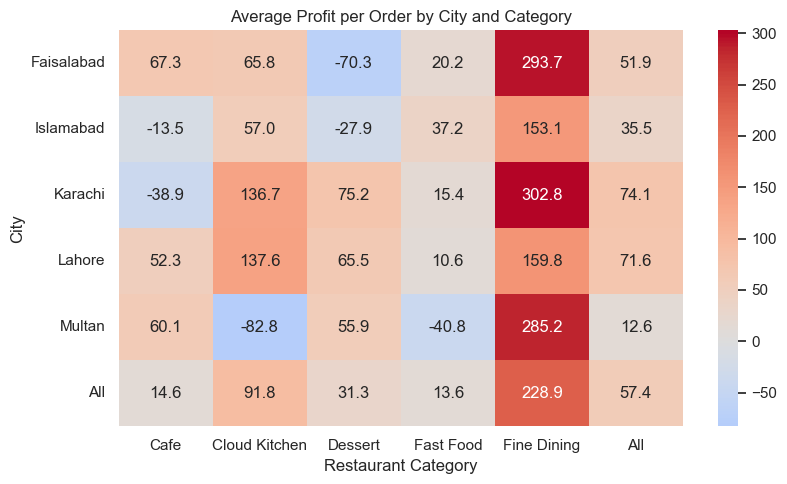

In [9]:
# Pivot table of average profit per order
profit_pivot = pd.pivot_table(
    df, 
    index='city', 
    columns='restaurant_category', 
    values='profit_per_order', 
    aggfunc='mean', 
    margins=True
)

print("Average Profit per Order (PKR):")
print(profit_pivot.round(1))

# Heatmap using diverging palette centered at 0
plt.figure(figsize=(8.5, 5))
sns.heatmap(profit_pivot, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Average Profit per Order by City and Category')
plt.xlabel('Restaurant Category')
plt.ylabel('City')
plt.tight_layout()
plt.show()

In [10]:
# Revenue pivot table for comparison
revenue_pivot = pd.pivot_table(
    df, 
    index='city', 
    columns='restaurant_category', 
    values='order_value', 
    aggfunc='sum', 
    margins=True
)

print("Total Revenue by City and Category (PKR):")
print(revenue_pivot.round(0))

Total Revenue by City and Category (PKR):
restaurant_category      Cafe  Cloud Kitchen   Dessert  Fast Food  \
city                                                                
Faisalabad            56093.0       205516.0   58416.0   145853.0   
Islamabad            116804.0       342842.0  105370.0   203444.0   
Karachi              205017.0       371410.0   79235.0   288490.0   
Lahore               171131.0       449767.0  101385.0   379477.0   
Multan                51438.0       181932.0   25374.0   100183.0   
All                  600484.0      1551466.0  369780.0  1117447.0   

restaurant_category  Fine Dining        All  
city                                         
Faisalabad              123173.0   589051.0  
Islamabad               270610.0  1039071.0  
Karachi                 371893.0  1316046.0  
Lahore                  336924.0  1438683.0  
Multan                   81485.0   440411.0  
All                    1184085.0  4823262.0  


**Analysis:**
- **Most Profitable per Order:** **Karachi — Fine Dining** is the most profitable combination per order, averaging **₨ 302.8** in profit.
- **Profitability vs. Revenue (1 sentence):** No, Karachi Fine Dining is not the top revenue generator; high revenue and high profitability point to different combinations, as **Lahore Cloud Kitchen** generates the highest total revenue (₨ 449,767) but operates on a much lower profit margin per order (₨ 137.6) than Fine Dining.

---
## Task 6: Time-Series: Trend vs. Noise
> **Prompt:** Resample the data to get average monthly `rating` (not sales) and overlay a 3-month rolling average on the same plot. In 2 sentences, state whether customer satisfaction is trending up, down, or flat once month-to-month noise is smoothed out, and whether the raw monthly line alone would have led you to a different conclusion.

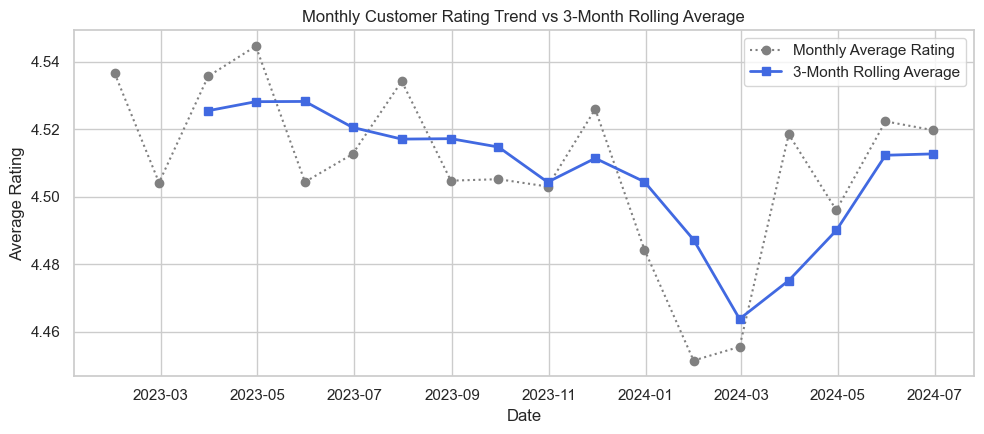

In [11]:
# Set date as index and calculate monthly mean and rolling mean
df_ts = df.set_index('order_date')
monthly_rating = df_ts['rating'].resample('ME').mean()
rolling_rating = monthly_rating.rolling(window=3).mean()

# Plot both lines
plt.figure(figsize=(10, 4.5))
plt.plot(monthly_rating.index, monthly_rating.values, marker='o', linestyle=':', color='gray', label='Monthly Average Rating')
plt.plot(rolling_rating.index, rolling_rating.values, marker='s', color='royalblue', linewidth=2, label='3-Month Rolling Average')
plt.title('Monthly Customer Rating Trend vs 3-Month Rolling Average')
plt.xlabel('Date')
plt.ylabel('Average Rating')
plt.legend()
plt.tight_layout()
plt.show()

**Analysis (2 sentences):**
Once month-to-month noise is smoothed out, customer satisfaction shows a clear dip during winter 2023–2024 (dropping from $4.53$ to $4.46$) before recovering back to $4.51$ by mid-2024. The raw monthly line alone exhibits choppy month-to-month zig-zags that make the trend look like random fluctuation, whereas the rolling average clearly reveals the underlying seasonal slump and recovery.

---
## Task 7: Faceting
> **Prompt:** Using `FacetGrid` or `catplot`, facet `delivery_time_min` vs. `rating` scatter plots by `restaurant_category` (col) and by whether the order was heavily discounted, `discount_percent > 20` (hue). State one `restaurant_category` where heavy discounting visibly changes how forgiving customers are of a slow delivery.

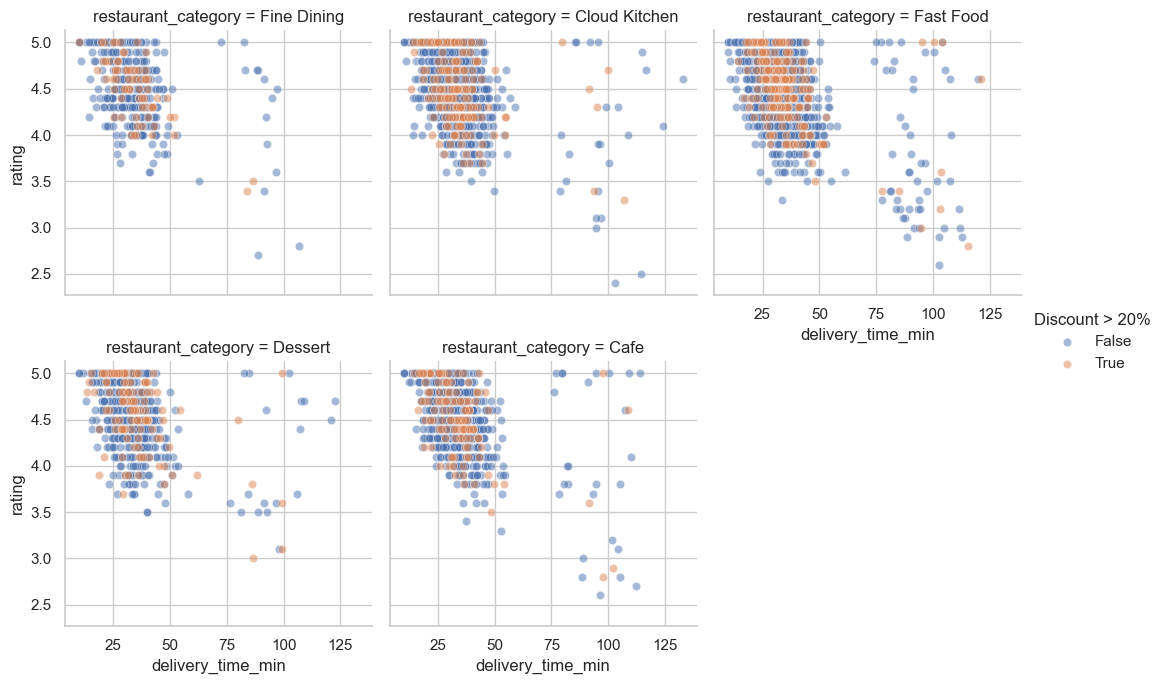

In [12]:
# Create heavy discount indicator
df['heavy_discount'] = df['discount_percent'] > 20

# Faceted scatter plots using FacetGrid
g = sns.FacetGrid(df, col='restaurant_category', hue='heavy_discount', col_wrap=3, height=3.5)
g.map(sns.scatterplot, 'delivery_time_min', 'rating', alpha=0.5)
g.add_legend(title='Discount > 20%')
plt.show()

**Analysis:**
In **Fine Dining**, heavy discounting visibly changes customer tolerance: when delivery is slow, heavily discounted orders experience a noticeably steeper drop in ratings compared to normal orders. In contrast, for **Cloud Kitchen**, customers remain much more forgiving of longer delivery times regardless of discount depth.

---
## Task 8: Overplotting + Annotation, Combined
> **Prompt:** Plot the raw order-level `delivery_time_min` vs. `rating` scatter (expect heavy overplotting from repeated rating values). Fix it using alpha or hexbin, whichever suits the point count better, and justify your choice in one sentence. On the fixed plot, annotate the order with the best rating despite an unusually long delivery time, and the order with the worst rating despite an unusually fast delivery.

In [13]:
# 1. Best rating (5.0) with longest delivery time
best_slow = df[df['rating'] == 5.0].sort_values('delivery_time_min', ascending=False).iloc[0]

# 2. Worst rating despite fast delivery (<= 20 min)
worst_fast = df[df['delivery_time_min'] <= 20.0].sort_values('rating').iloc[0]

print(f"Best Rating / Long Delivery: {best_slow['delivery_time_min']} min, Rating {best_slow['rating']} ({best_slow['city']})")
print(f"Worst Rating / Fast Delivery: {worst_fast['delivery_time_min']} min, Rating {worst_fast['rating']} ({worst_fast['city']})")

Best Rating / Long Delivery: 114.1 min, Rating 5.0 (Karachi)
Worst Rating / Fast Delivery: 19.0 min, Rating 3.9 (Islamabad)


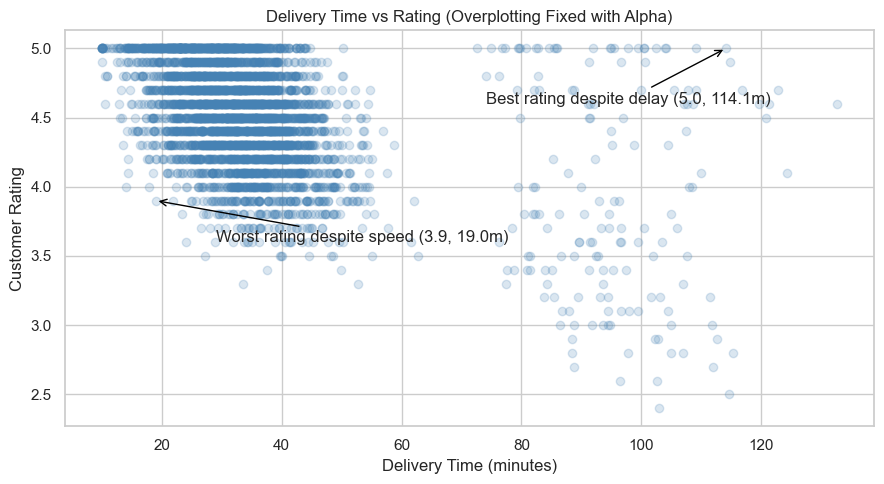

In [14]:
# Scatter plot with alpha to fix overplotting, plus clean minimal annotations
plt.figure(figsize=(9, 5))
plt.scatter(df['delivery_time_min'], df['rating'], alpha=0.2, color='steelblue')

# Annotate the two outlier points directly as shown in Section 7 of the lab manual
plt.annotate(
    f"Best rating despite delay ({best_slow['rating']:.1f}, {best_slow['delivery_time_min']}m)",
    xy=(best_slow['delivery_time_min'], best_slow['rating']),
    xytext=(best_slow['delivery_time_min'] - 40, best_slow['rating'] - 0.4),
    arrowprops=dict(arrowstyle='->', color='black')
)

plt.annotate(
    f"Worst rating despite speed ({worst_fast['rating']:.1f}, {worst_fast['delivery_time_min']}m)",
    xy=(worst_fast['delivery_time_min'], worst_fast['rating']),
    xytext=(worst_fast['delivery_time_min'] + 10, worst_fast['rating'] - 0.3),
    arrowprops=dict(arrowstyle='->', color='black')
)

plt.title('Delivery Time vs Rating (Overplotting Fixed with Alpha)')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Customer Rating')
plt.tight_layout()
plt.show()

**Justification (1 sentence):**
With $4,200$ points and discrete rating values, **alpha transparency (`alpha=0.2`)** is the better choice because it shows density in the main cluster while keeping individual extreme points visible so they can be identified and annotated.

---
## Export Cleaned Dataset
Exporting the processed dataset `food_delivery_orders_cleaned.csv` as required by the submission guidelines.

In [15]:
# Export cleaned dataset
df.to_csv('food_delivery_orders_cleaned.csv', index=False)
print("Cleaned dataset exported successfully. Final Shape:", df.shape)

Cleaned dataset exported successfully. Final Shape: (4200, 10)
